# Inferring two real pellets from transmitted terahertz fields

This notebook actively extracts both refractive-index and absorption spectra from all native measured samples. The independent original run is a standard-method comparison, not material truth. Data: Leung and coauthors, Cambridge Apollo version2, CC BY4.0. The unknowns are optical properties of whole PE and lactose/PE pellets, distinct from recovering source pulses or fitting acquisition noise.

For a slab thickness d, amplitude A=4n/(n+1)² exp(−αd/2), delay phase φ=2πf(n−1)d/c. Here n is real index, α intensity absorption in inverse metres, fHz and c the speed of light. Solve n=1+cφ/(2πfd), then α=2log[4n/(A(n+1)²)]/d. Display α incm⁻¹. Real interface factors approximate weak boundary loss; isolated primary pulses exclude Fabry–Pérot repetitions.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd()if (Path.cwd()/'src').is_dir()else Path.cwd().parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,THICKNESSES_MM
from src.solvers import reconstruct
from src.physics_model import slab_transfer
from src.visualization import metrics,plot_optical
t,e=load_data(root/'data/raw_data.npz');start=time.perf_counter()
fresh,d=reconstruct(t,e,return_diagnostics=True);runtime=time.perf_counter()-start
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)as a:original={k:a[k]for k in fresh}
original_measurements=json.loads((root/'notebooks/reference_outputs/upstream_measurements.json').read_text())
f=d['frequency_hz'];plots={};trace={};measurements={'fresh_runtime_seconds':runtime,'original_runtime_seconds':original_measurements['runtime_seconds'],'agreement':{k:[metrics(fresh[k][0,i],original[k][0,i])for i in range(2)]for k in fresh},'negative_alpha_bins':[int(np.sum(x<0))for x in fresh['absorption_coefficient'][0]]}
print(json.dumps(measurements,indent=2))


{
  "fresh_runtime_seconds": 0.008778000017628074,
  "original_runtime_seconds": 0.025229600025340915,
  "agreement": {
    "real_index": [
      {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      {
        "ncc": 1.0000000000000002,
        "nrmse": 0.0
      }
    ],
    "absorption_coefficient": [
      {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      {
        "ncc": 1.0000000000000002,
        "nrmse": 0.0
      }
    ]
  },
  "negative_alpha_bins": [
    276,
    157
  ]
}


## The acquisition and the retained delay

The original three scans have slightly different time coordinates. Locate each largest absolute field peak, apply the same15ps half-width Hann window, and pad on a common time base while preserving relative pulse arrival times. Original phase referencing uses the positive maximum; its role differs from absolute-peak window centering. A15ps half-width suppresses separated delayed reflections. All3008 input samples remain available; windowing is the selected published analysis, not a smaller benchmark acquisition.

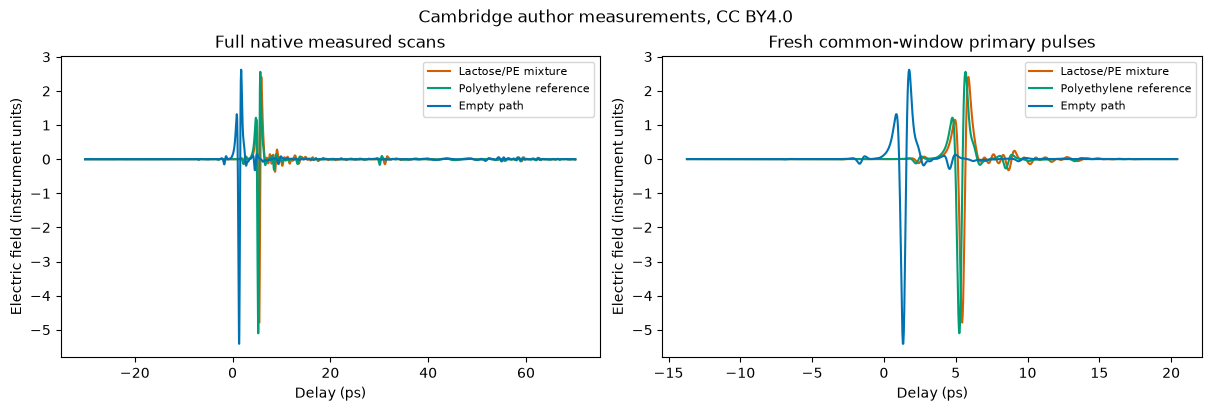

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
colors=['#D55E00','#009E73','#0072B2'];names=['Lactose/PE mixture','Polyethylene reference','Empty path']
for i in range(3):
    ax[0].plot(t[i],e[i],label=names[i],color=colors[i]);ax[1].plot(d['windowed'][i,1],d['windowed'][i,0],label=names[i],color=colors[i])
for a in ax:a.set(xlabel='Delay (ps)',ylabel='Electric field (instrument units)');a.legend(fontsize=8)
ax[0].set_title('Full native measured scans');ax[1].set_title('Fresh common-window primary pulses');fig.suptitle('Cambridge author measurements, CC BY4.0')
plots['measured_pulses']=fig;plt.close('all');display(fig)


## Fourier ratios, phase and optical spectra

Zero-pad the common window to the next power of two times8; this interpolates frequency sampling without improving the independent physical resolution. Correct phase wraps by removing peak-time ramps, unwrapping the residual phase and estimating its integer2π offset by a linear fit over0.2–0.4THz. Retain0.2–2.5THz. Both materials and both physical quantities are recomputed locally and compared with the independently executed original. Signed negative apparent absorption is preserved and visibly marked against zero.

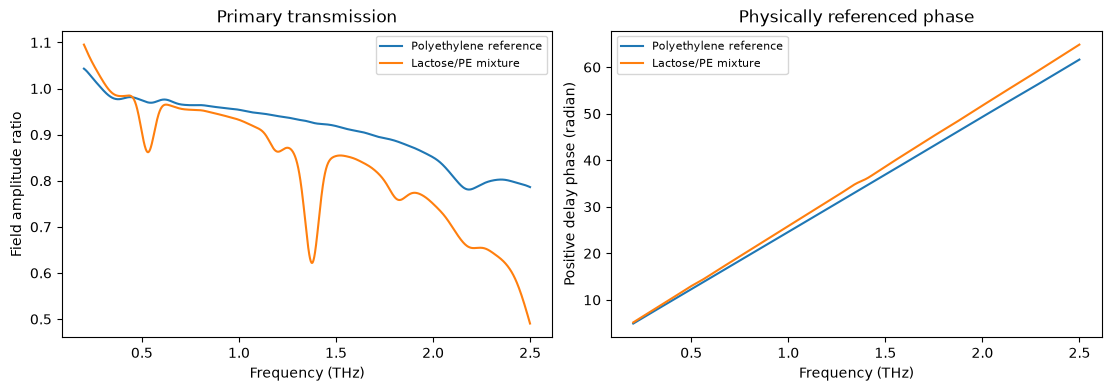

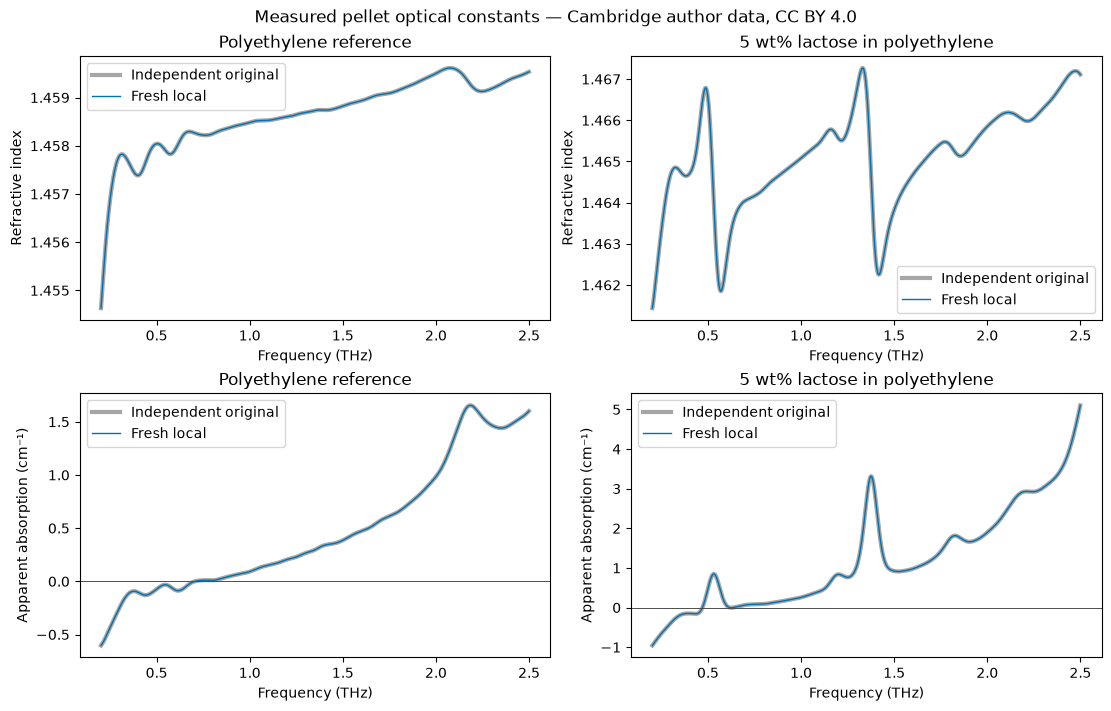

In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,3.8),layout='constrained')
for i,name in enumerate(names[:2][::-1]):
    ax[0].plot(f*1e-12,d['amplitude'][i],label=name);ax[1].plot(f*1e-12,d['phase'][i],label=name)
ax[0].set(ylabel='Field amplitude ratio',title='Primary transmission');ax[1].set(ylabel='Positive delay phase (radian)',title='Physically referenced phase')
for a in ax:a.set_xlabel('Frequency (THz)');a.legend(fontsize=8)
plots['spectral_transfer']=fig;plt.close(fig);display(fig)
plots['optical_constants']=plot_optical(f,fresh,original);plt.close(plots['optical_constants']);display(plots['optical_constants'])


## Physical consistency and limitations

Forward-evaluate each inferred slab spectrum against the measured-window transmission and delay. These residuals test algebraic consistency, not independent empirical accuracy, since the same two data quantities determine the two unknowns. Negative apparent absorption may reflect beam coupling, thickness uncertainty, finite windowing or calibration mismatch; it must not be interpreted as a passive material producing energy. The next experiments quantify analysis and calibration sensitivity without inventing true spectra.

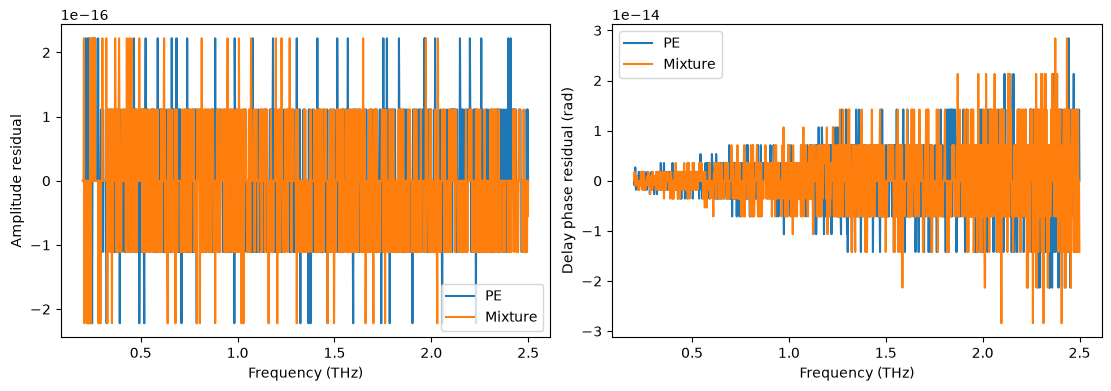

In [4]:
forward_amp=[];forward_phase=[]
for i,thickness in enumerate(THICKNESSES_MM):
    a,p=slab_transfer(fresh['real_index'][0,i],fresh['absorption_coefficient'][0,i],f,thickness*1e-3);forward_amp.append(a);forward_phase.append(p)
forward_amp=np.array(forward_amp);forward_phase=np.array(forward_phase)
measurements['forward_max_amplitude_error']=float(np.max(abs(forward_amp-d['amplitude'])));measurements['forward_max_phase_error_rad']=float(np.max(abs(forward_phase-d['phase'])))
fig,ax=plt.subplots(1,2,figsize=(11,3.8),layout='constrained')
for i,label in enumerate(['PE','Mixture']):ax[0].plot(f*1e-12,forward_amp[i]-d['amplitude'][i],label=label);ax[1].plot(f*1e-12,forward_phase[i]-d['phase'][i],label=label)
ax[0].set_ylabel('Amplitude residual');ax[1].set_ylabel('Delay phase residual (rad)')
for a in ax:a.set_xlabel('Frequency (THz)');a.legend()
plots['forward_consistency']=fig;plt.close(fig);display(fig)


## Apodisation, delay span and thickness sensitivity

Recompute10,15and20ps Hann half-widths, plus a15ps boxcar failure comparison. Longer spans may retain more etalon contamination; rectangular truncation causes spectral leakage. Also recompute both spectra with independently perturbed nominal thicknesses±1%, an explicitly hypothetical calibration-sensitivity experiment rather than a measured uncertainty interval. These preserve the tutorial's emphasis on time span, consistent apodisation and exact known sample thickness; effective-medium inversion to pure lactose, other experimental geometries and conventional missing-baseline assumptions are outside this task's whole-pellet unknowns and are not shown as fresh results.

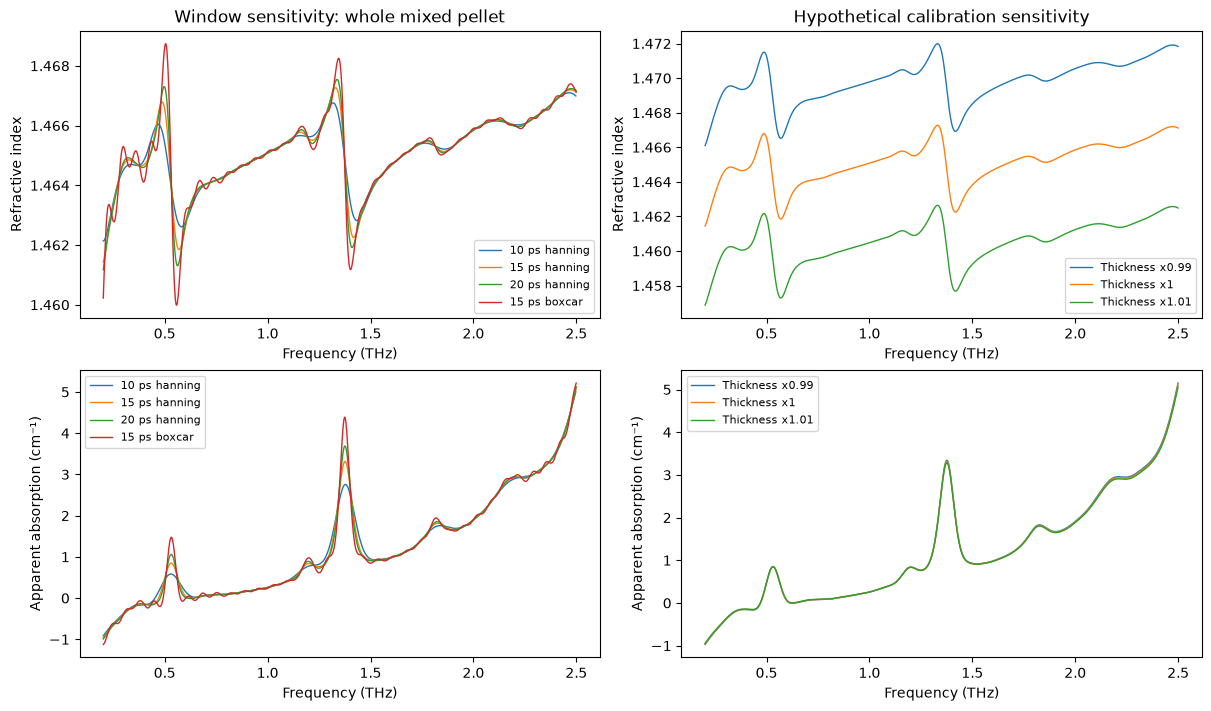

{
  "fresh_runtime_seconds": 0.008778000017628074,
  "original_runtime_seconds": 0.025229600025340915,
  "agreement": {
    "real_index": [
      {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      {
        "ncc": 1.0000000000000002,
        "nrmse": 0.0
      }
    ],
    "absorption_coefficient": [
      {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      {
        "ncc": 1.0000000000000002,
        "nrmse": 0.0
      }
    ]
  },
  "negative_alpha_bins": [
    276,
    157
  ],
  "forward_max_amplitude_error": 2.220446049250313e-16,
  "forward_max_phase_error_rad": 2.842170943040401e-14,
  "thickness_one_percent_index_max_change": 0.004626423508197419
}


In [5]:
variants={}
for width,win in [(10.,'hanning'),(15.,'hanning'),(20.,'hanning'),(15.,'boxcar')]:
    result,diag=reconstruct(t,e,half_width=width,window=win,return_diagnostics=True);variants[f'{width:g} ps {win}']=(result,diag['frequency_hz'])
thickness_variants={factor:reconstruct(t,e,thicknesses_mm=THICKNESSES_MM*factor)for factor in(.99,1.,1.01)}
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for label,(result,freq)in variants.items():
    for row,key in enumerate(('real_index','absorption_coefficient')):ax[row,0].plot(freq*1e-12,result[key][0,1],label=label,lw=1)
for factor,result in thickness_variants.items():
    for row,key in enumerate(('real_index','absorption_coefficient')):ax[row,1].plot(f*1e-12,result[key][0,1],label=f'Thickness x{factor:g}',lw=1)
for row in range(2):
    for col in range(2):ax[row,col].set(xlabel='Frequency (THz)',ylabel='Refractive index'if row==0 else 'Apparent absorption (cm⁻¹)');ax[row,col].legend(fontsize=8)
ax[0,0].set_title('Window sensitivity: whole mixed pellet');ax[0,1].set_title('Hypothetical calibration sensitivity')
plots['analysis_sensitivity']=fig;plt.close(fig);display(fig)
measurements['thickness_one_percent_index_max_change']=float(np.max(abs(thickness_variants[1.01]['real_index']-fresh['real_index'])))
print(json.dumps(measurements,indent=2))


## Independent evaluation

Judge every quantity and material independently, with no clipping or gain adjustment. Numerical agreement with an original extraction is distinct from true optical-property accuracy. The original deterministic repeat was identical; evaluation uses nonzero numerical tolerances, supplemented by independent analytic slab, unit-conversion, delay-preservation and FFT phase tests.

In [6]:
import importlib.util,tempfile
spec=importlib.util.spec_from_file_location('judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with tempfile.TemporaryDirectory()as directory:
    path=Path(directory)/'fresh.npz';np.savez_compressed(path,**fresh);report,status=judge.evaluate(path)
assert status==0;print(json.dumps(report,indent=2))


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "real_index_0_ncc": 1.0,
    "real_index_0_nrmse": 0.0,
    "real_index_1_ncc": 1.0000000000000002,
    "real_index_1_nrmse": 0.0,
    "absorption_coefficient_0_ncc": 1.0,
    "absorption_coefficient_0_nrmse": 0.0,
    "absorption_coefficient_1_ncc": 1.0000000000000002,
    "absorption_coefficient_1_nrmse": 0.0
  },
  "thresholds": {
    "real_index_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "real_index_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "real_index_1_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "real_index_1_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "absorption_coefficient_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "absorption_coefficient_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "absorption_coefficient_1_ncc": {
      "comparison": ">=",
    